In [44]:
import pygplates
import numpy as np
import matplotlib.pyplot as plt
import sys
sys.path.append('/Users/Simon/GIT/GPlatesClassStruggle/')
from reconstruction_classes import *

import plate_driver as pdriver

%load_ext autoreload
%autoreload 2

M2016 = ReconstructionModel('Matthews++2016')
M2016.add_rotation_model('/Users/simon/GIT/agegrid-dev/input_files/Rotations/Matthews_etal_GPC_2016_410-0Ma_GK07.rot')
M2016.add_static_polygons('/Users/simon/GIT/agegrid-dev/input_files/StaticPolygons/Muller_etal_AREPS_2016_StaticPolygons.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_MesozoicCenozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_Paleozoic_PlateTopologies.gpml')
M2016.add_dynamic_polygons('/Users/simon/GIT/agegrid-dev/input_files/DynamicPolygons/Matthews_etal_GPC_2016_TopologyBuildingBlocks.gpml')


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [45]:
delta_time = 10.
forces = ['slab_pull','slab_suction']
slab_suction_to_slab_pull_ratio = 0.25
    
results = []    

for reconstruction_time in np.arange(10,400,10):
    
    snapshot = M2016.plate_snapshot(reconstruction_time)

    result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time,
                                                    forces, slab_suction_to_slab_pull_ratio)
    
    results.append((reconstruction_time,result))
    
    

Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting shared sub-segment "NAM subduction COB"
    subduction zone feature is missing subduction polarity property or it is set to "Unknown".
Unable to find the overriding plate of the subducting s

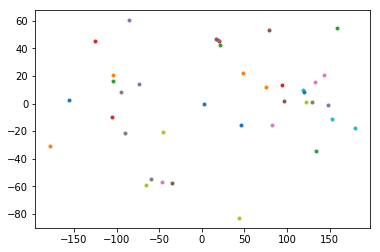

In [46]:
for result in results:
    
    plt.figure()
    for point in zip(*result[1])[1]:
        plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], '.')
        
    plt.show()
    break
    


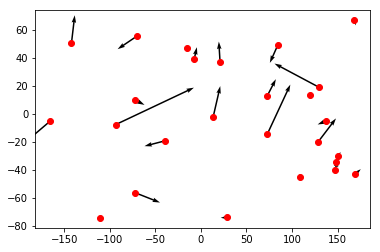

In [47]:
for result in results[5:6]:
    
    plt.figure()
    for point,vel in zip(zip(*result[1])[1],zip(*result[1])[4]):
        if vel is not None:
            plt.plot(point.to_lat_lon()[1], point.to_lat_lon()[0], 'ro')
            plt.quiver(point.to_lat_lon()[1],
                       point.to_lat_lon()[0],
                       vel.get_y(),
                       vel.get_x(),
                       color='k', units='xy', scale=0.02, width=1.5)
    break

In [58]:
target_plate_id = 301
reconstruction_time = 10

snapshot = M2016.plate_snapshot(reconstruction_time)

forces = ['slab_pull']
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces, slab_suction_to_slab_pull_ratio)
    
print pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon()

forces = ['slab_suction']
result = pdriver.get_torque_for_plate_polygon(snapshot, target_plate_id, reconstruction_time, delta_time,
                                              forces, slab_suction_to_slab_pull_ratio)
    
print pygplates.PointOnSphere(result[2].to_normalised().to_xyz()).to_lat_lon()


(57.10020788731053, 123.35880402521143)
(1.9351336116323565, 165.74186781937732)


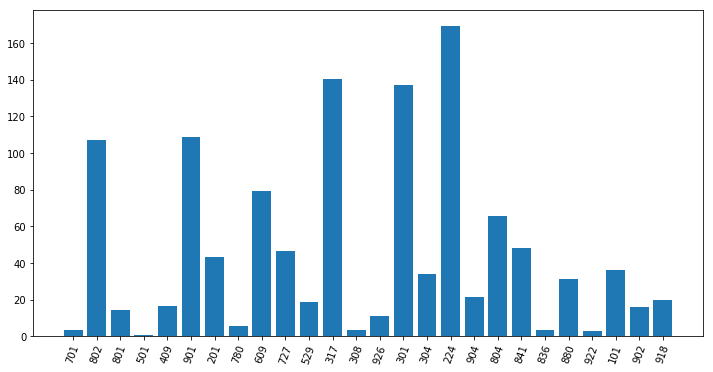

In [80]:
reconstruction_time = 60.
forces = ['slab_pull','slab_suction']

snapshot = M2016.plate_snapshot(reconstruction_time)

result = pdriver.get_torques_for_plate_snapshot(snapshot, reconstruction_time, delta_time,
                                                forces, slab_suction_to_slab_pull_ratio)

plate_ids = []
angles = []

for res in result:
    if res[4] is not None:
        angle = pygplates.Vector3D.angle_between(res[4],res[6])
        plate_ids.append(res[0])
        angles.append(np.degrees(angle))
    
    
width = 0.8
fig, ax = plt.subplots(figsize=(12,6))
plt.bar(np.arange(len(angles)),angles)
ax.set_xticks(np.arange(len(angles)))
ax.set_xticklabels(plate_ids,rotation=70)
plt.show()
        